# 03 - Modelling

**Goal:** predict the entry price (`base_rate_inr`) of a lane from the rate-card attributes alone.

**Why it matters:** if a model can say what a lane "should" cost, a pricing analyst can spot lanes that are priced oddly before a contract is renewed.

**Metric:** mean absolute error (MAE) of the **log** rate. A log-scale error of 0.20 means the prediction is typically about 20% off, whatever the price level. That is the right yardstick here because a INR 5 miss on a INR 30 lane matters far more than a INR 5 miss on a INR 3,000 lane. I also report R-squared and a plain-percentage error so the result is easy to read.

**Honest validation:** lanes from one customer resemble each other, so a random split would let the model peek at the same customer in training and testing. Everything below keeps each customer on one side of the split, which mimics the real use case: pricing a customer the model has never seen.

In [1]:
import json
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyRegressor
from sklearn.ensemble import GradientBoostingRegressor, RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.model_selection import GridSearchCV, GroupKFold, LeaveOneGroupOut, cross_validate
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42
FIG_DIR = Path("../reports/figures")
lanes = pd.read_csv("../data/processed/rate_lanes_clean.csv", parse_dates=["effective_date"])

## 1. Inputs, target and the customer-level split

I leave out `add_rate_inr` on purpose: it is the per-extra-weight price from the same rate card and would hand the model half the answer. Customer and contract IDs are also left out so the model cannot memorise who the customer is.

In [2]:
categorical = ["lead_region", "product_code", "product_type", "charge_basis", "freight_type",
               "origin_type", "dest_type", "origin_zone", "dest_zone"]
numeric = ["min_weight_kg", "first_slab_end_kg", "n_slabs", "same_zone", "vol_divisor", "months_since_2025"]

X = lanes[categorical + numeric].copy()
# a handful of lanes have an open-ended first slab (stored as 99999 kg); cap it so it cannot dominate
X["first_slab_end_kg"] = X["first_slab_end_kg"].fillna(10).clip(upper=10)
y = lanes["log_base_rate"]
groups = lanes["customer_id"]

# Only 8 customers exist, so the split is chosen by a stated rule rather than at random:
# hold out two mid-sized customers that each carry both the D and I products.
# The rule was fixed before any model was fitted.
TEST_CUSTOMERS = ["CUST-004", "CUST-005"]
is_test = groups.isin(TEST_CUSTOMERS).values
train_idx, test_idx = np.where(~is_test)[0], np.where(is_test)[0]
X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]
g_train = groups.iloc[train_idx]

print(f"Train: {len(X_train):,} lanes from {g_train.nunique()} customers")
print(f"Test:  {len(X_test):,} lanes from {groups.iloc[test_idx].nunique()} customers (never touched until section 5)")
assert set(g_train).isdisjoint(set(groups.iloc[test_idx])), "a customer leaked across the split"

Train: 1,056 lanes from 6 customers
Test:  240 lanes from 2 customers (never touched until section 5)


In [3]:
def make_pipeline(model, scale=False):
    prep = ColumnTransformer([
        ("cats", OneHotEncoder(handle_unknown="ignore", min_frequency=5, sparse_output=False), categorical),
        ("nums", StandardScaler() if scale else "passthrough", numeric),
    ])
    return Pipeline([("prep", prep), ("model", model)])

candidates = {
    "Baseline (median)": make_pipeline(DummyRegressor(strategy="median")),
    "Ridge": make_pipeline(Ridge(alpha=1.0), scale=True),
    "Random forest": make_pipeline(RandomForestRegressor(n_estimators=300, random_state=SEED)),
    "Gradient boosting": make_pipeline(GradientBoostingRegressor(random_state=SEED)),
}

## 2. Compare models with grouped cross-validation

Leave-one-customer-out: each fold sets aside one whole customer, trains on the rest and scores on the customer it has not seen. The baseline simply predicts the median log rate, so any real model has to beat that to be worth keeping.

In [4]:
cv = LeaveOneGroupOut()
scoring = {"mae": "neg_mean_absolute_error", "r2": "r2"}
rows = []
for name, pipe in candidates.items():
    res = cross_validate(pipe, X_train, y_train, groups=g_train, cv=cv, scoring=scoring)
    rows.append({
        "model": name,
        "cv_mae_log": -res["test_mae"].mean(),
        "mae_std": res["test_mae"].std(),
        "cv_r2": res["test_r2"].mean(),
    })
cv_table = pd.DataFrame(rows).sort_values("cv_mae_log").round(3)
cv_table

,model,cv_mae_log,mae_std,cv_r2
1,Ridge,0.191,0.163,0.899
3,Gradient boosting,0.262,0.256,0.791
2,Random forest,0.274,0.279,0.849
0,Baseline (median),1.449,0.873,-0.707


Read the table like this: `cv_mae_log` is the typical log error (lower is better), `mae_std` shows how much that bounces between folds, and `cv_r2` is the share of price variation explained. A wide `mae_std` tells us that results depend on which customer is held out, which is a real feature of this data and not a bug.

### Why the split matters: a quick leakage check

To see how much a careless split would flatter the model, I score the same random forest two ways: holding out whole customers (honest) and holding out random lanes (the usual shortcut).

In [5]:
from sklearn.model_selection import KFold
rf = candidates["Random forest"]
honest = cross_validate(rf, X_train, y_train, groups=g_train, cv=LeaveOneGroupOut(),
                        scoring="neg_mean_absolute_error")["test_score"].mean()
shortcut = cross_validate(rf, X_train, y_train, cv=KFold(5, shuffle=True, random_state=SEED),
                          scoring="neg_mean_absolute_error")["test_score"].mean()
print(f"Held-out customers : MAE {-honest:.3f}")
print(f"Random lane split  : MAE {-shortcut:.3f}   <- looks better, but only because the customer was already seen")

Held-out customers : MAE 0.274
Random lane split  : MAE 0.114   <- looks better, but only because the customer was already seen


## 3. Tune every model with grid search

In [6]:
grids = {
    "Ridge": {"model__alpha": [0.1, 1, 3, 10, 30]},
    "Random forest": {
        "model__n_estimators": [200, 400],
        "model__max_depth": [None, 12],
        "model__min_samples_leaf": [1, 3],
    },
    "Gradient boosting": {
        "model__n_estimators": [150, 300],
        "model__learning_rate": [0.05, 0.1],
        "model__max_depth": [2, 3],
    },
}
searches = {}
for name, grid in grids.items():
    gs = GridSearchCV(candidates[name], grid, cv=cv, scoring="neg_mean_absolute_error")
    gs.fit(X_train, y_train, groups=g_train)
    searches[name] = gs
    print(f"{name}: best CV MAE {-gs.best_score_:.3f} with {gs.best_params_}")

Ridge: best CV MAE 0.188 with {'model__alpha': 3}


Random forest: best CV MAE 0.272 with {'model__max_depth': None, 'model__min_samples_leaf': 1, 'model__n_estimators': 200}


Gradient boosting: best CV MAE 0.241 with {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__n_estimators': 300}


Ridge gets a grid too, so the simplest model has the same chance to win as the complicated ones. The grids are small on purpose. With about a thousand training lanes, a large search mostly finds noise, and every extra setting tried makes the best score look a little luckier than it is.

## 4. Pick the winner using training data only

The rule is fixed in advance: lowest tuned cross-validated error wins, and a tie goes to the simpler model.

In [7]:
tuned_scores = {name: -gs.best_score_ for name, gs in searches.items()}
winner_name = min(tuned_scores, key=tuned_scores.get)
winner = searches[winner_name].best_estimator_
print("Selected model:", winner_name)

Selected model: Ridge


If a plain ridge regression wins, that is useful information, not a disappointment. Prices here move by fixed percentages with product, region and zone, which is exactly the kind of pattern a straight line on the log scale captures. Complicated models only pay off when the pattern has twists a line cannot follow, and they cost more to explain.

## 5. One look at the held-out test customers

This is the only time the test set is used. It answers the question a pricing team would ask: how does the model do on a customer it has never seen?

In [8]:
def score(pipe, X_part, y_part):
    pred = pipe.predict(X_part)
    actual_inr, pred_inr = np.exp(y_part), np.exp(pred)
    return {
        "mae_log": mean_absolute_error(y_part, pred),
        "r2_log": r2_score(y_part, pred),
        "median_abs_pct_error": float(np.median(np.abs(pred_inr - actual_inr) / actual_inr) * 100),
    }

baseline = candidates["Baseline (median)"].fit(X_train, y_train)
test_scores = {"Baseline (median)": score(baseline, X_test, y_test), winner_name: score(winner, X_test, y_test)}
pd.DataFrame(test_scores).T.round(3)

,mae_log,r2_log,median_abs_pct_error
Baseline (median),1.438,-0.358,39.221
Ridge,0.108,0.995,9.298


In [9]:
# bootstrap the test lanes to see how much the MAE could move by chance
rng = np.random.default_rng(SEED)
pred_test = winner.predict(X_test)
abs_err = np.abs(pred_test - y_test.values)
boot = [rng.choice(abs_err, size=len(abs_err), replace=True).mean() for _ in range(2000)]
ci_low, ci_high = np.percentile(boot, [2.5, 97.5])

base_err = np.abs(baseline.predict(X_test) - y_test.values)
gain = base_err.mean() - abs_err.mean()
print(f"Test MAE (log): {abs_err.mean():.3f}   95% interval: {ci_low:.3f} to {ci_high:.3f}")
print(f"Improvement over the median baseline: {gain:.3f} log points ({gain / base_err.mean():.0%} lower error)")

Test MAE (log): 0.108   95% interval: 0.099 to 0.118
Improvement over the median baseline: 1.330 log points (92% lower error)


That interval is narrower than it deserves to be. It only reflects lane-to-lane noise inside two customers, not the fact that a different pair of customers would give a different answer. The leave-one-customer-out spread in section 2 (`mae_std`) is the better guide to how much to trust the headline number, and it is large.

## 6. Where does the model go wrong?

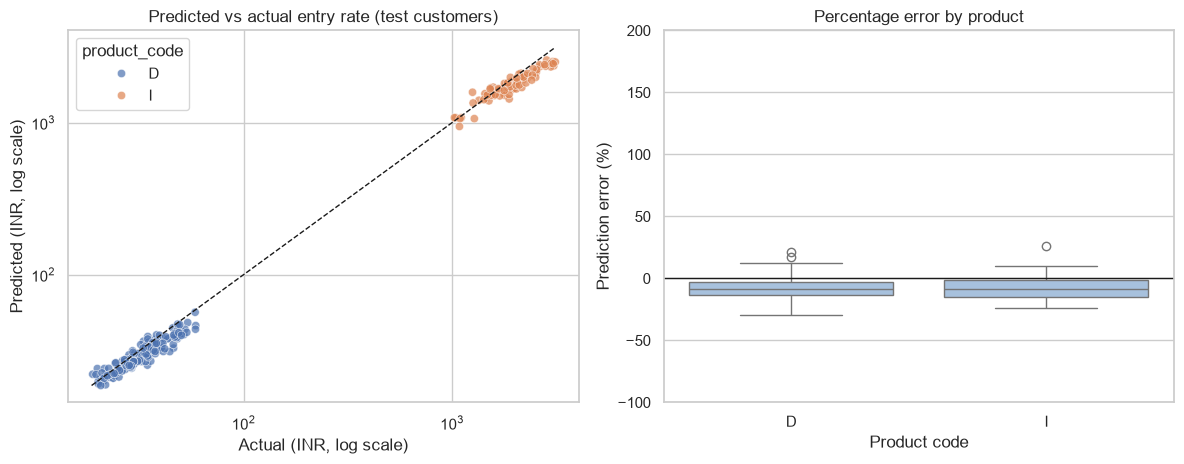

In [10]:
results = X_test.copy()
results["actual_inr"] = np.exp(y_test.values)
results["predicted_inr"] = np.exp(pred_test)
results["pct_error"] = (results["predicted_inr"] - results["actual_inr"]) / results["actual_inr"] * 100

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
sns.scatterplot(data=results, x="actual_inr", y="predicted_inr", hue="product_code", alpha=0.7, ax=axes[0])
lims = [results[["actual_inr", "predicted_inr"]].min().min(), results[["actual_inr", "predicted_inr"]].max().max()]
axes[0].plot(lims, lims, "k--", linewidth=1)
axes[0].set(xscale="log", yscale="log", title="Predicted vs actual entry rate (test customers)",
            xlabel="Actual (INR, log scale)", ylabel="Predicted (INR, log scale)")
sns.boxplot(data=results, x="product_code", y="pct_error", ax=axes[1], color="#9ec1e6")
axes[1].axhline(0, color="k", linewidth=1)
axes[1].set(title="Percentage error by product", xlabel="Product code", ylabel="Prediction error (%)")
axes[1].set_ylim(-100, 200)
plt.tight_layout()
fig.savefig(FIG_DIR / "06_predicted_vs_actual.png", dpi=150)
plt.show()

In [11]:
by_product = results.groupby("product_code").agg(
    lanes=("actual_inr", "size"),
    median_abs_pct_error=("pct_error", lambda s: s.abs().median()),
).round(1)
by_product

,lanes,median_abs_pct_error
product_code,,
D,162,9.3
I,78,9.3


## 7. What is the model relying on?

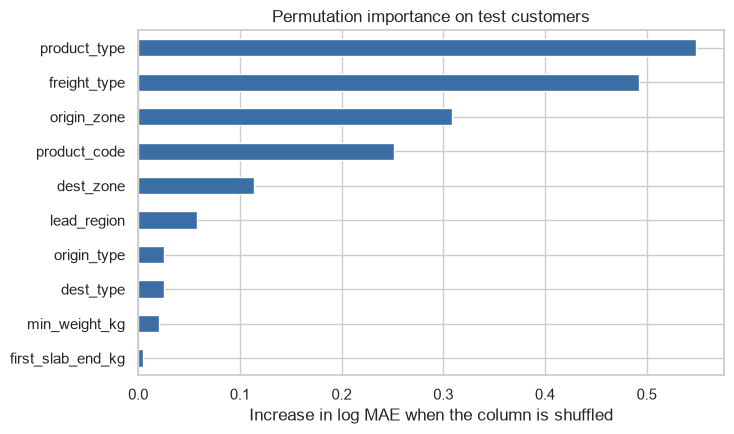

In [12]:
imp = permutation_importance(winner, X_test, y_test, scoring="neg_mean_absolute_error",
                             n_repeats=20, random_state=SEED)
importance = (pd.Series(imp.importances_mean, index=X_test.columns)
              .sort_values(ascending=True).tail(10))
fig, ax = plt.subplots(figsize=(7.5, 4.5))
importance.plot.barh(ax=ax, color="#3b6ea5")
ax.set(title="Permutation importance on test customers", xlabel="Increase in log MAE when the column is shuffled")
plt.tight_layout()
fig.savefig(FIG_DIR / "07_feature_importance.png", dpi=150)
plt.show()

Shuffling a column and watching the error rise is a straightforward way to see which inputs matter. It does not prove cause and effect, only reliance.

## 8. Save the model and the numbers

In [13]:
Path("../models").mkdir(exist_ok=True)
joblib.dump(winner, "../models/rate_model.joblib")

summary = {
    "selected_model": winner_name,
    "seed": SEED,
    "train_lanes": int(len(X_train)),
    "test_lanes": int(len(X_test)),
    "cv_table": cv_table.to_dict(orient="records"),
    "tuned_cv_mae": {k: round(v, 4) for k, v in tuned_scores.items()},
    "best_params": {k: v.best_params_ for k, v in searches.items()},
    "test": test_scores,
    "test_mae_ci95": [round(ci_low, 4), round(ci_high, 4)],
    "error_by_product": by_product.reset_index().to_dict(orient="records"),
}
Path("../reports/model_results.json").write_text(json.dumps(summary, indent=2, default=str))
results.round(2).to_csv("../reports/test_predictions.csv", index=False)
print("Saved model, results and test predictions")

Saved model, results and test predictions


Next: `04_findings_and_recommendations.ipynb`.